In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
pd.set_option("display.max_columns", None)

df = pd.read_csv("C:/Users/lenovo/Downloads/ShopSphere-Customer-Intelligence/data/cleaned/superstore_cleaned.csv")

# Convert dates (CSV loses datetime format)
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

In [9]:
print(f"Total Sales : ${df['Sales'].sum():,.2f}")
print(f"Total Profit : ${df['Profit'].sum():,.2f}")
print("Total Orders :", df["Order ID"].nunique())
print("Total Customers :", df["Customer ID"].nunique())
print("Total Products :", df["Product ID"].nunique())

Total Sales : $2,297,200.86
Total Profit : $286,397.02
Total Orders : 5009
Total Customers : 793
Total Products : 1862


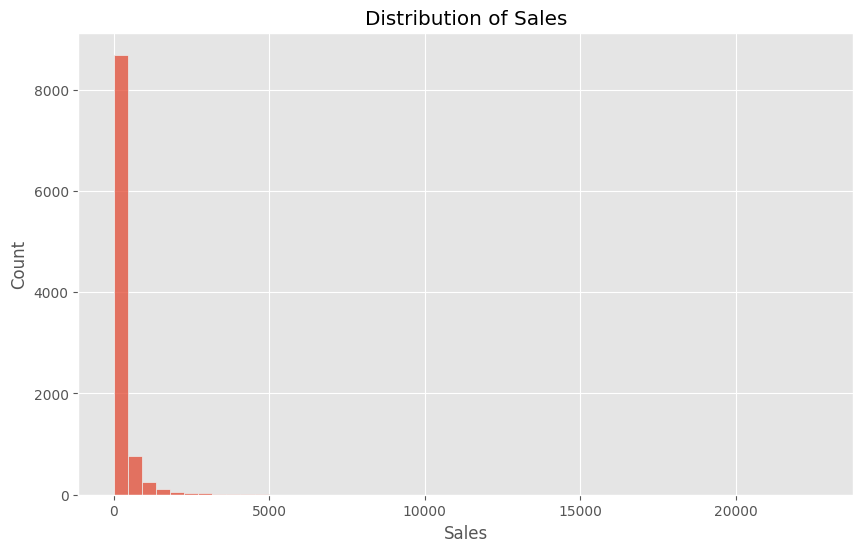

In [10]:
plt.figure(figsize=(10,6))

sns.histplot(df["Sales"], bins=50)

plt.title("Distribution of Sales")
plt.show()

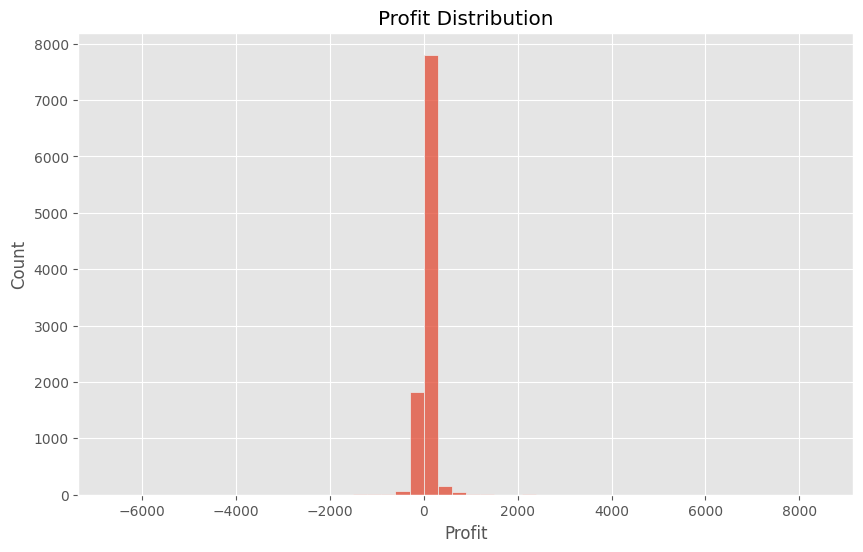

In [11]:
plt.figure(figsize=(10,6))

sns.histplot(df["Profit"], bins=50)

plt.title("Profit Distribution")

plt.show()

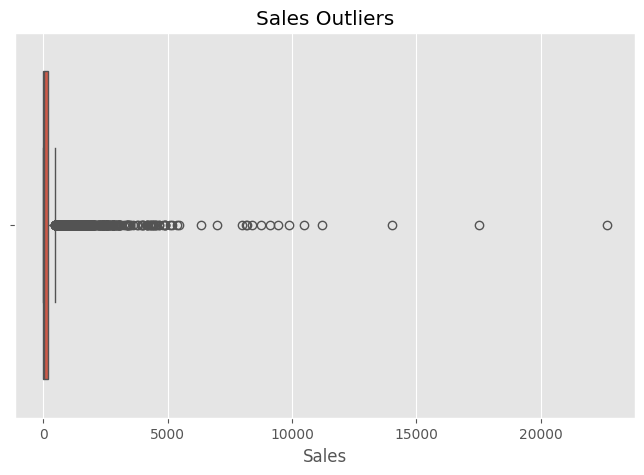

In [12]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Sales"])

plt.title("Sales Outliers")

plt.show()

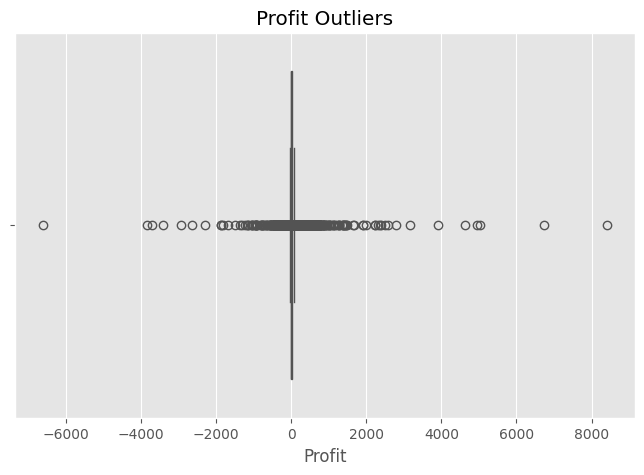

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Profit"])

plt.title("Profit Outliers")

plt.show()

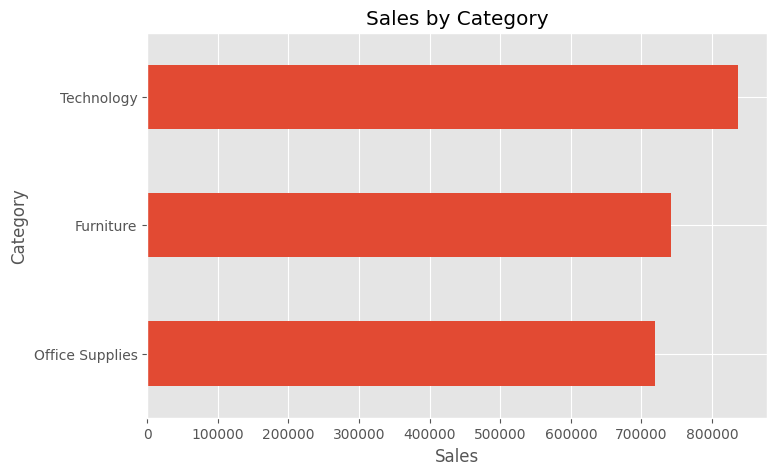

In [14]:
category_sales = df.groupby("Category")["Sales"].sum().sort_values()
plt.figure(figsize=(8,5))

category_sales.plot(kind="barh")

plt.title("Sales by Category")

plt.xlabel("Sales")

plt.show()

<Axes: xlabel='Category'>

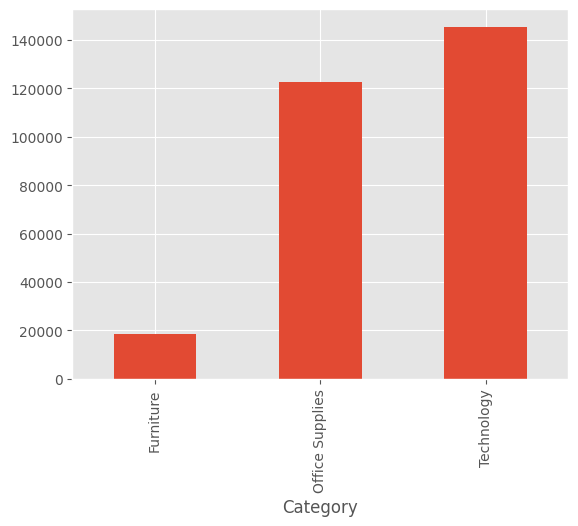

In [15]:
category_profit = df.groupby("Category")["Profit"].sum()
category_profit.plot(kind="bar")

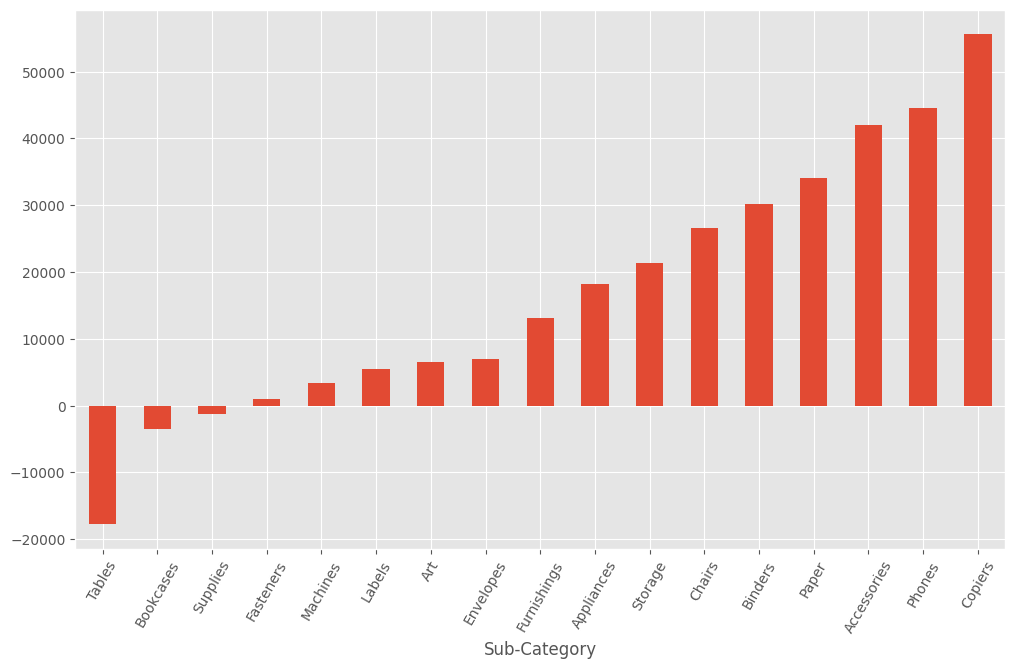

In [16]:
subcategory = df.groupby("Sub-Category")["Profit"].sum().sort_values()
plt.figure(figsize=(12,7))

subcategory.plot(kind="bar")

plt.xticks(rotation=60)

plt.show()


<Axes: xlabel='Region'>

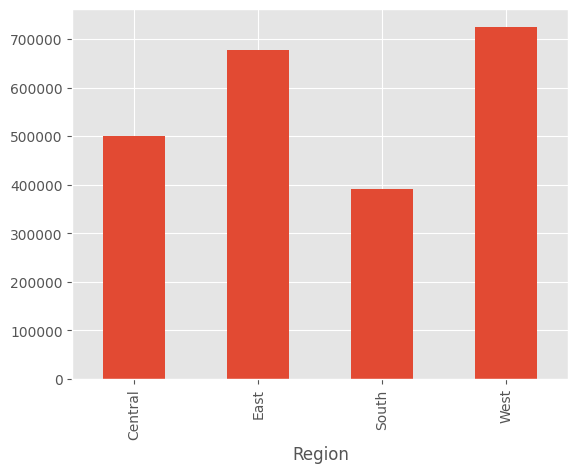

In [17]:
region_sales = df.groupby("Region")["Sales"].sum()
region_sales.plot(kind="bar")

<Axes: xlabel='Region'>

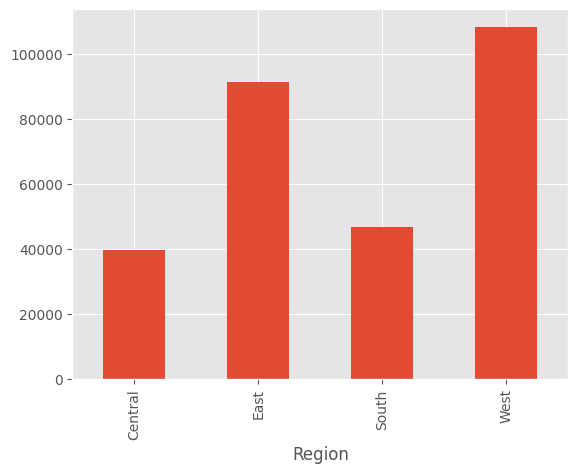

In [18]:
region_profit = df.groupby("Region")["Profit"].sum()
region_profit.plot(kind="bar")

In [19]:
top_states = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
top_states = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
bottom_states = (
    df.groupby("State")["Sales"]
    .sum()
    .sort_values()
    .head(10)
)

<Axes: >

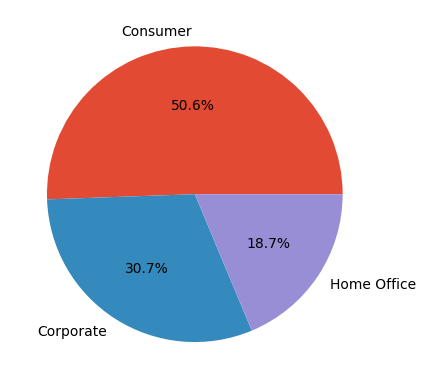

In [20]:
segment_sales = df.groupby("Segment")["Sales"].sum()
segment_sales.plot(kind="pie", autopct="%1.1f%%")

<Axes: xlabel='Ship Mode'>

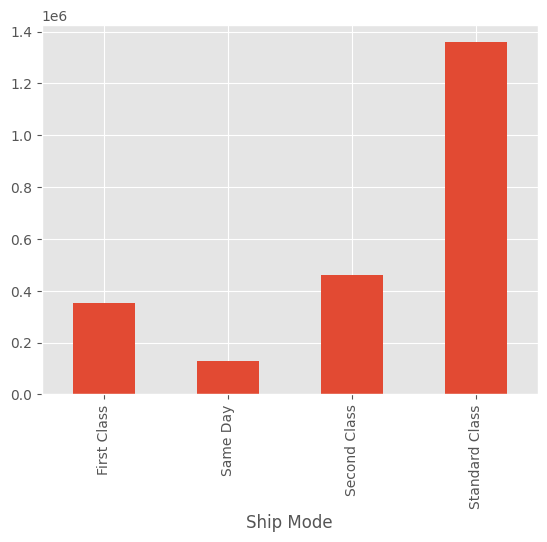

In [21]:
shipping = df.groupby("Ship Mode")["Sales"].sum()
shipping.plot(kind="bar")

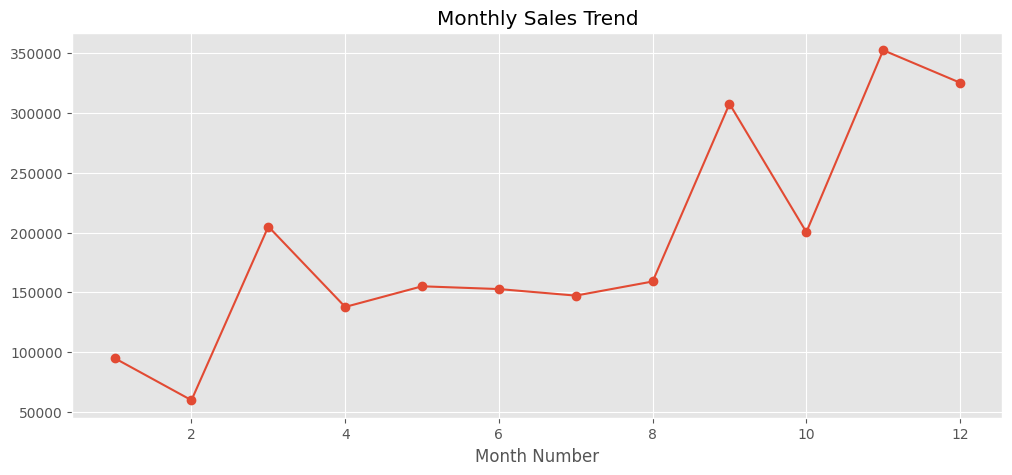

In [22]:
monthly_sales = (
    df.groupby("Month Number")["Sales"]
    .sum()
)
plt.figure(figsize=(12,5))

monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")

plt.show()

In [23]:
quarter_sales = (
    df.groupby("Quarter")["Sales"]
    .sum()
)
quarter_sales = (
    df.groupby("Quarter")["Sales"]
    .sum()
)

In [24]:
df["Delivery Days"].describe()
df["Delivery Days"].describe()

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Delivery Days, dtype: float64

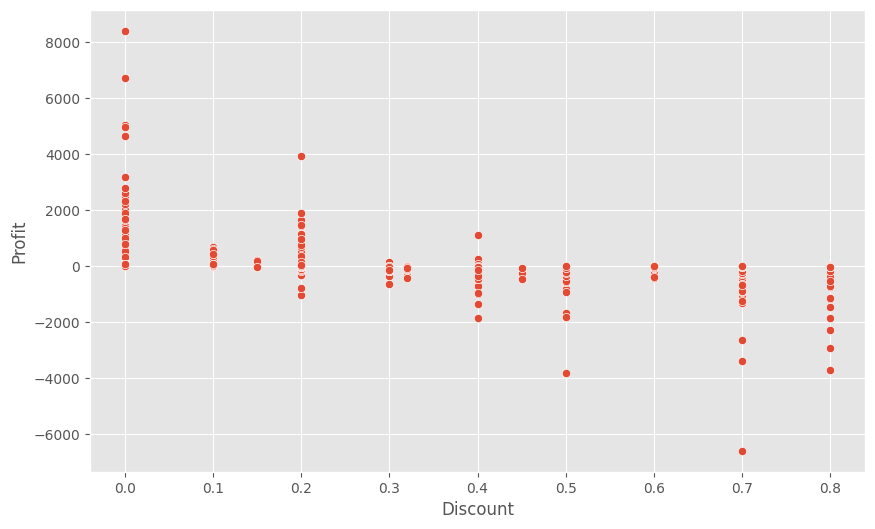

In [25]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Discount",
    y="Profit",
    data=df
)

plt.show()

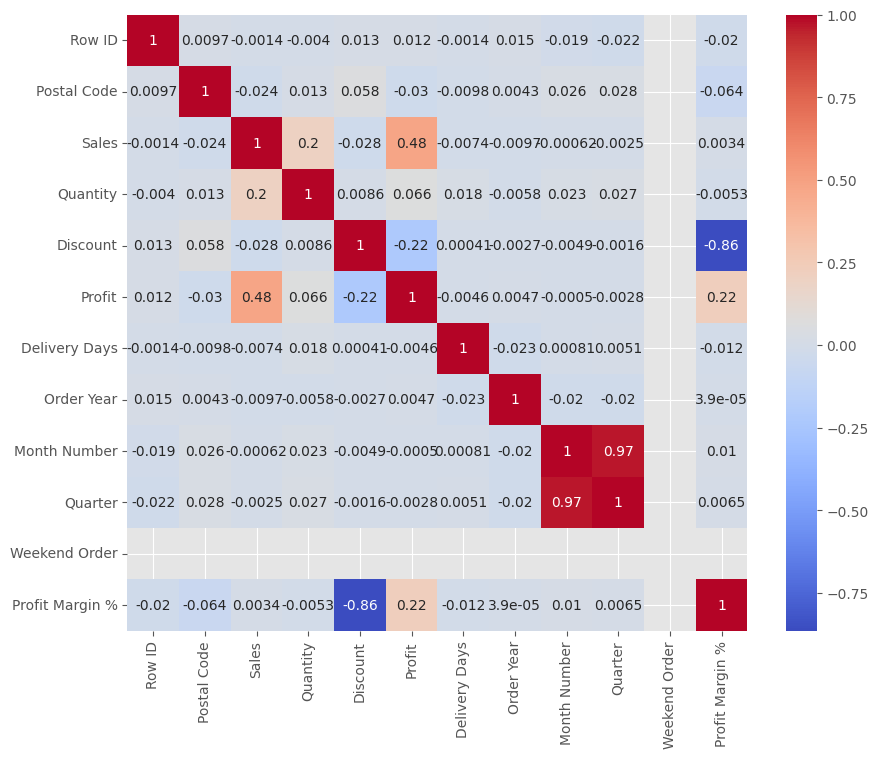

In [26]:
numeric = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

<Axes: ylabel='Product Name'>

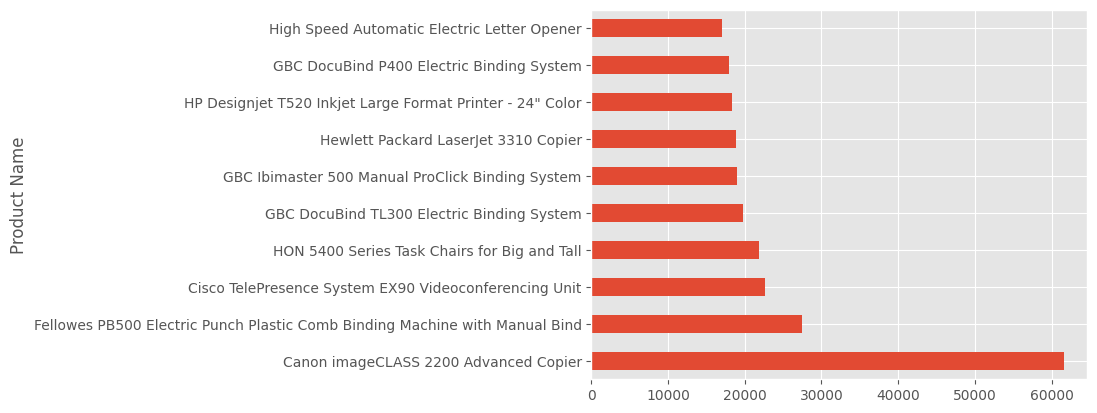

In [27]:
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
top_products.plot(kind="barh")

In [28]:
worst = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
    .head(10)
)

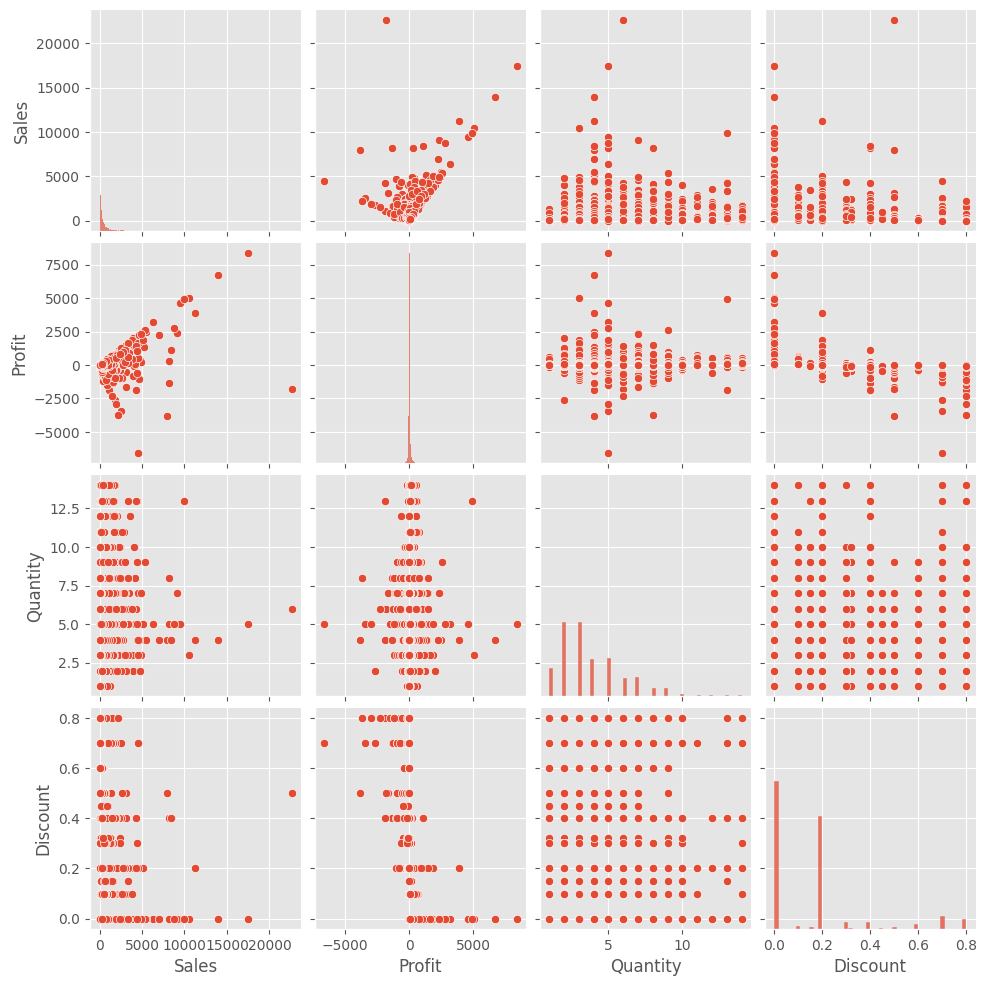

In [29]:
sns.pairplot(
    df[
        [
            "Sales",
            "Profit",
            "Quantity",
            "Discount"
        ]
    ]
)